# Неделя 1. EDA реализованной волатильности акций MOEX

Выборка: основная сессия, сетка 10 минут, `sample_start = 2023-01-01`; в анализ входят только полные дни (`is_complete`).

Определения: $$RV_t=\sum_{j=1}^{M} r_{t,j}^2, r_{t,j}=\ln P_{t,j}-\ln P_{t,j-1}, M=54$$ $$\log RV_t=\ln RV_t, ret_day = \sum_j r_{t,j}$$ — доходность «открытие–закрытие» основной сессии.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import acf, adfuller

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("pyproject.toml не найден выше текущего каталога")


ROOT = repo_root()
SAMPLE_START = pd.Timestamp("2023-01-01")
NLAGS = 60
REF = "SBER"

panel = pd.read_parquet(ROOT / "data" / "processed" / "panel.parquet")
panel["date"] = pd.to_datetime(panel["date"])
panel = panel[panel["date"] >= SAMPLE_START].sort_values(["secid", "date"]).reset_index(drop=True)
good = panel[panel["is_complete"] & panel["log_rv"].notna()].copy()
SECIDS = sorted(good["secid"].unique())
print(f"Строк в панели: {len(panel)}, полных дней: {len(good)}, тикеров: {len(SECIDS)}")

Строк в панели: 9692, полных дней: 9651, тикеров: 10


## 1. Обзор выборки

In [2]:
overview = panel.groupby("secid").agg(
    n_days=("rv", "size"), n_complete=("is_complete", "sum"),
    first=("date", "min"), last=("date", "max"),
)
overview["share_complete"] = (overview["n_complete"] / overview["n_days"]).round(4)
overview

,n_days,n_complete,first,last,share_complete
secid,,,,,
GAZP,976,972,2023-01-03,2026-11-03,0.9959
GMKN,972,967,2023-01-03,2026-11-03,0.9949
LKOH,976,972,2023-01-03,2026-11-03,0.9959
NVTK,976,972,2023-01-03,2026-11-03,0.9959
OZON,942,938,2023-01-03,2026-11-03,0.9958
PLZL,973,969,2023-01-03,2026-11-03,0.9959
ROSN,976,972,2023-01-03,2026-11-03,0.9959
SBER,976,972,2023-01-03,2026-11-03,0.9959
T,953,949,2023-01-03,2026-11-03,0.9958


In [3]:
def describe(s: pd.Series) -> pd.Series:
    return pd.Series({
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "skew": stats.skew(s), "ex_kurt": stats.kurtosis(s),
        "q01": s.quantile(0.01), "q99": s.quantile(0.99),
    })


def table(col: str) -> pd.DataFrame:
    return pd.DataFrame({s: describe(g[col]) for s, g in good.groupby("secid")}).T


tab_rv, tab_log = table("rv"), table("log_rv")
ann_vol = np.sqrt(252 * good.groupby("secid")["rv"].mean()) * 100
print("RV:")
display(tab_rv)
print("log RV:")
display(tab_log)
print("Оценка годовой волатильности, % = sqrt(252 * mean RV) * 100:")
display(ann_vol.round(1).to_frame("ann_vol_pct"))

RV:


,mean,median,std,skew,ex_kurt,q01,q99
GAZP,0.000260,0.000155,0.000306,3.288156,15.312436,0.000022,0.001613
GMKN,0.000286,0.000195,0.000305,4.190145,29.385457,0.000027,0.001558
LKOH,0.000197,0.000122,0.000271,5.936828,53.975131,0.000019,0.001358
NVTK,0.000312,0.000218,0.000333,3.899479,22.624365,0.000032,0.001629
OZON,0.000456,0.000275,0.001195,23.379317,641.027634,0.000050,0.002297
PLZL,0.000355,0.000202,0.001158,24.708421,697.102124,0.000038,0.002462
ROSN,0.000237,0.000156,0.000303,6.887048,76.775491,0.000020,0.001462
SBER,0.000134,0.000086,0.000179,7.948731,103.126436,0.000012,0.000715
T,0.000251,0.000135,0.000402,7.247178,81.258610,0.000016,0.001819
VTBR,0.000334,0.000204,0.000882,23.744857,663.171601,0.000027,0.002170


log RV:


,mean,median,std,skew,ex_kurt,q01,q99
GAZP,-8.722774,-8.772140,0.961900,0.100475,-0.175002,-10.723807,-6.429533
GMKN,-8.520629,-8.541895,0.840368,0.026340,0.292255,-10.532523,-6.464654
LKOH,-8.962384,-9.014718,0.873864,0.331790,0.651943,-10.887387,-6.601690
NVTK,-8.425938,-8.433001,0.830737,0.009005,0.609927,-10.334805,-6.419949
OZON,-8.146032,-8.200278,0.842106,0.451126,1.310660,-9.899617,-6.076693
PLZL,-8.439285,-8.506889,0.840422,0.641013,1.907767,-10.174066,-6.007051
ROSN,-8.742401,-8.768704,0.860397,0.129472,0.396578,-10.831278,-6.528044
SBER,-9.336757,-9.355483,0.898185,0.043033,0.367504,-11.331244,-7.243319
T,-8.846917,-8.909648,1.027137,0.097457,0.415068,-11.066009,-6.310391
VTBR,-8.503760,-8.499422,0.913742,0.282329,0.675173,-10.530560,-6.133109


Оценка годовой волатильности, % = sqrt(252 * mean RV) * 100:


,ann_vol_pct
secid,
GAZP,25.6
GMKN,26.8
LKOH,22.3
NVTK,28.0
OZON,33.9
PLZL,29.9
ROSN,24.4
SBER,18.4
T,25.2


## 2. RV и log RV во времени

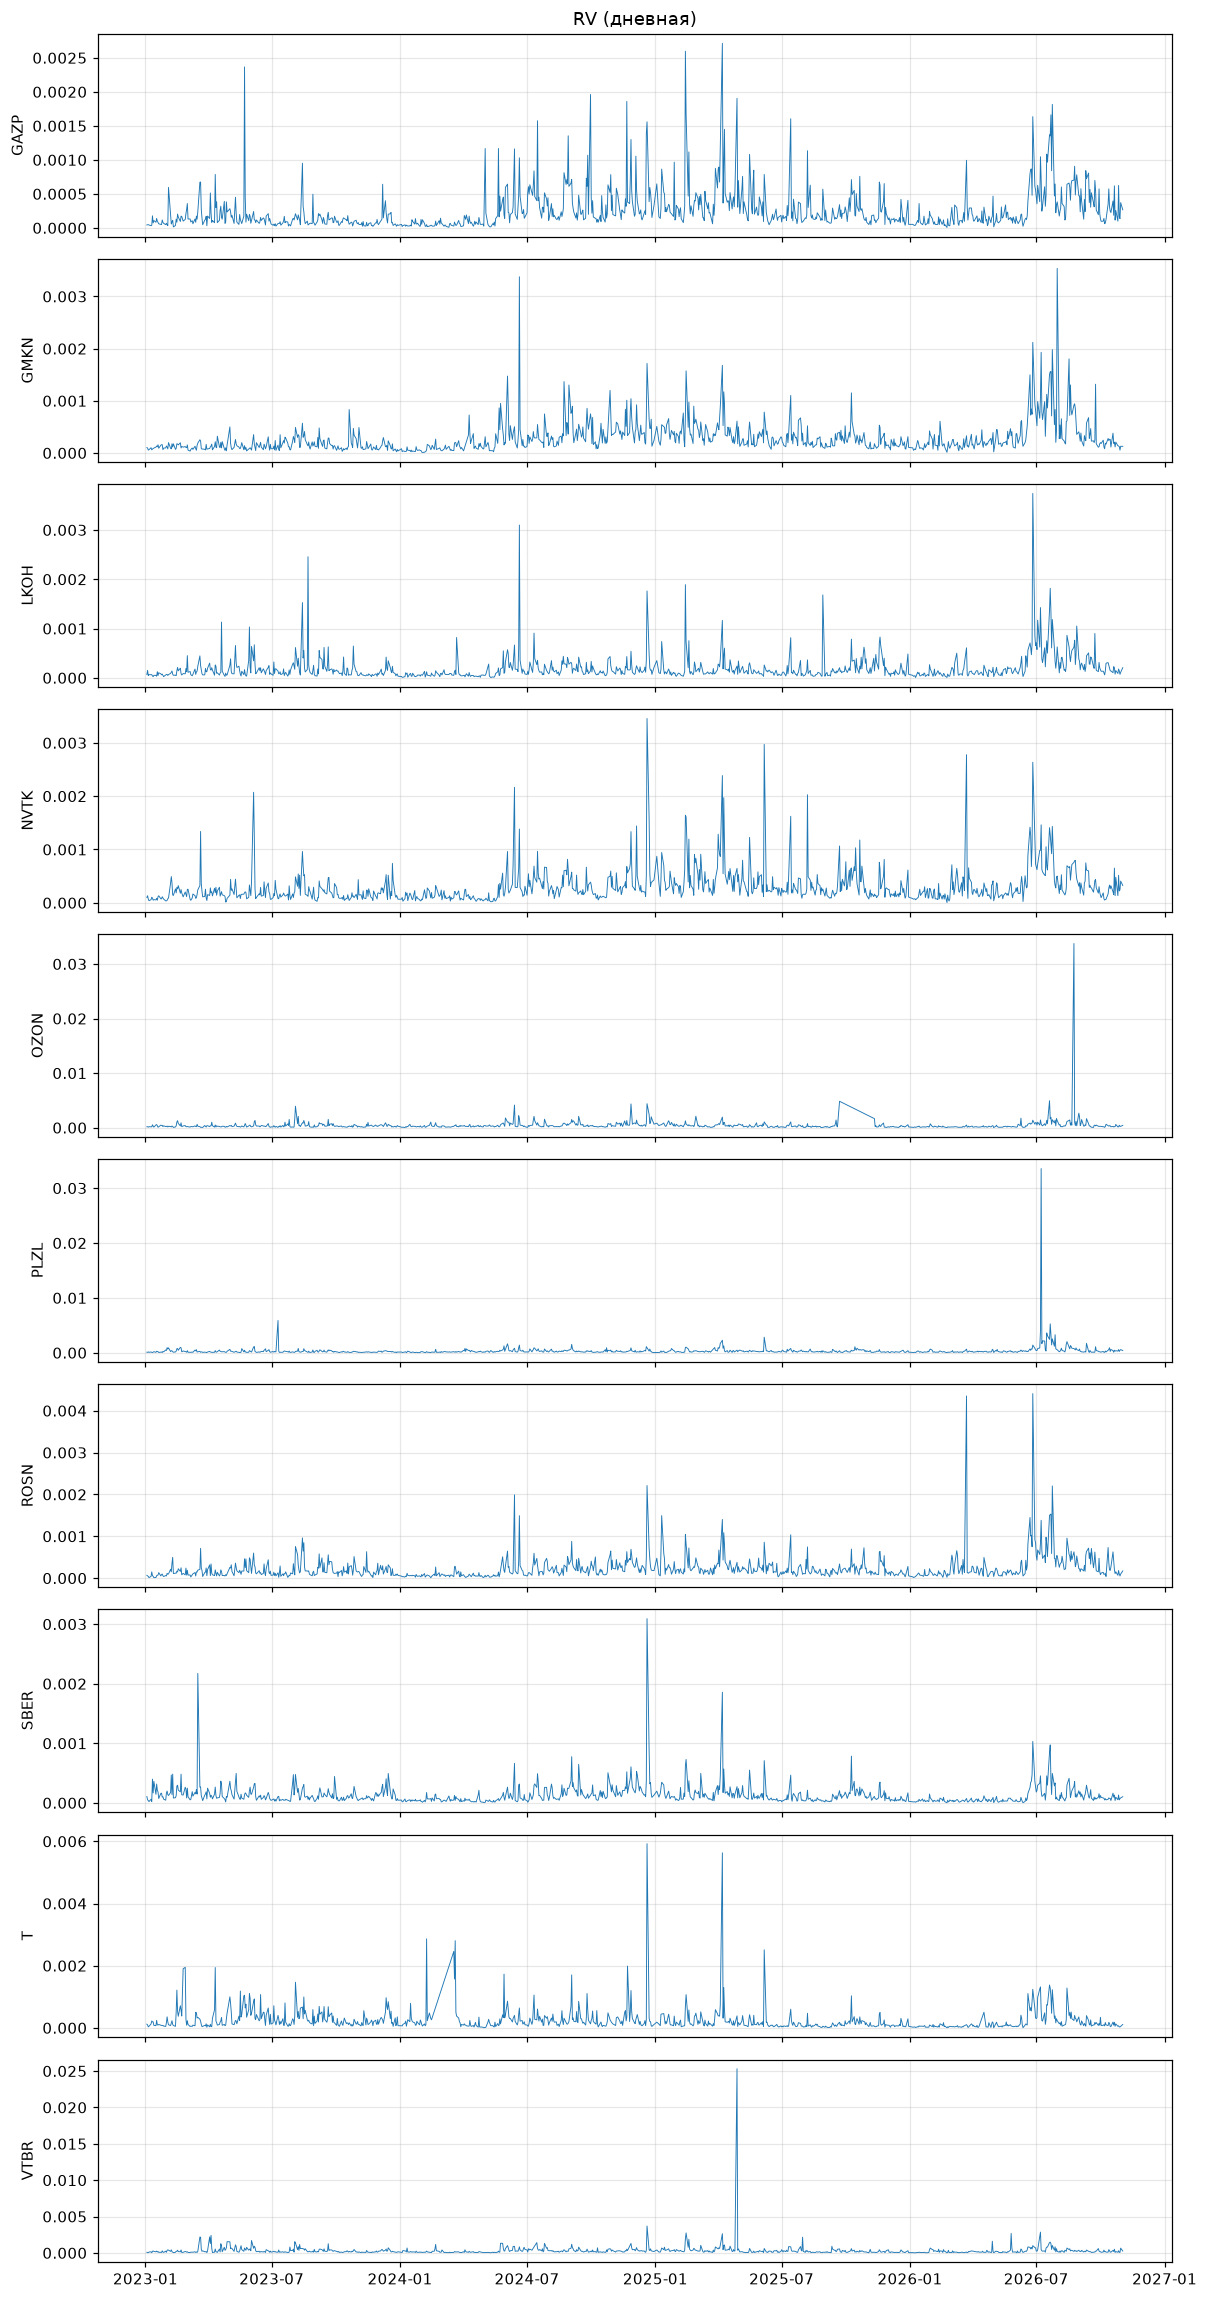

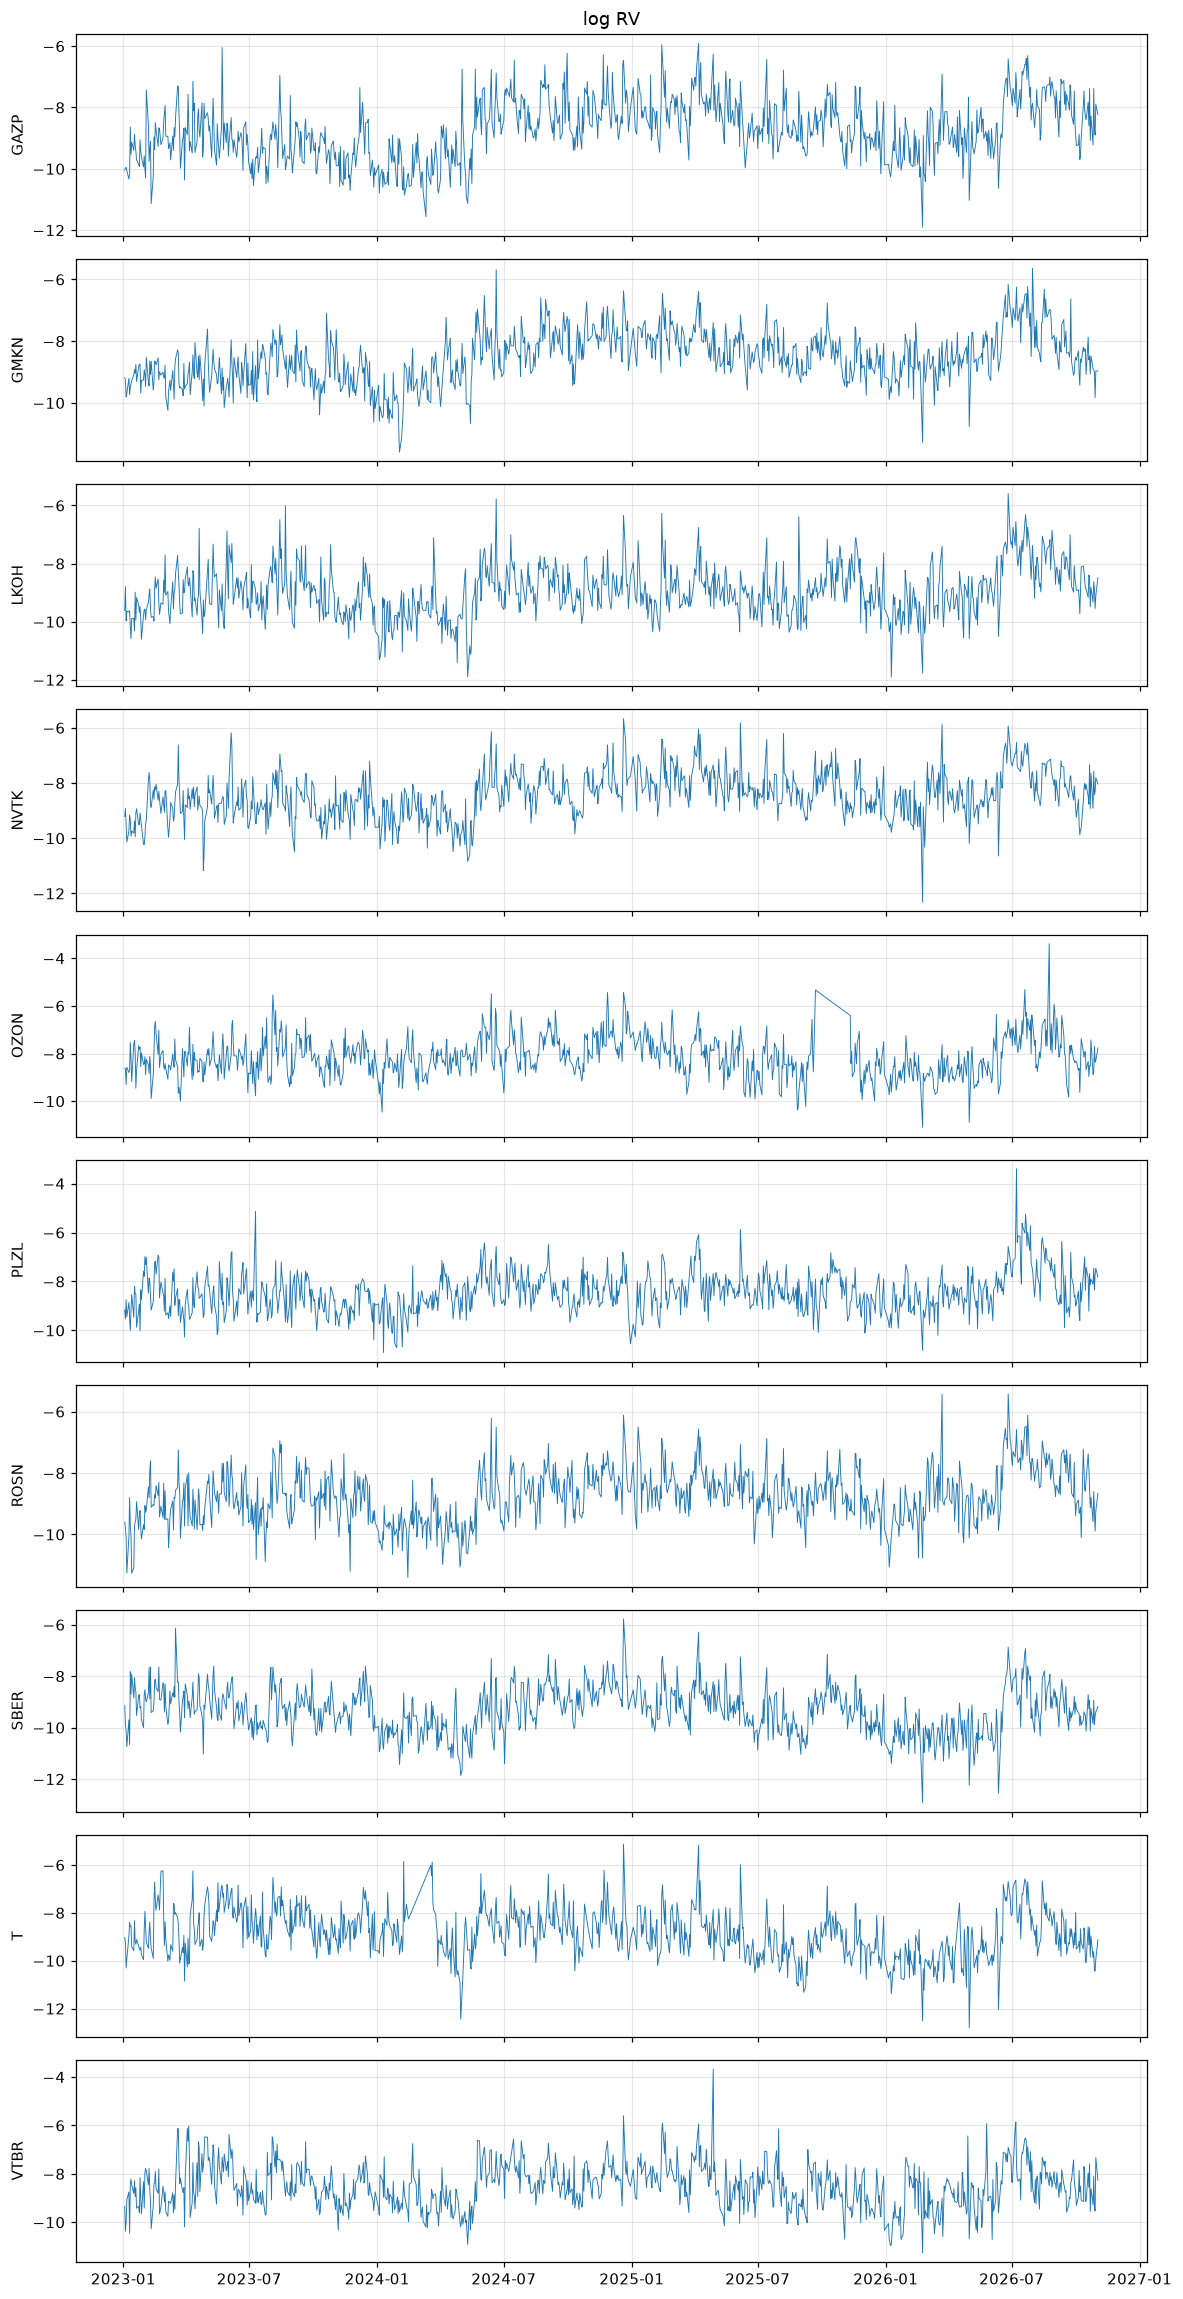

In [4]:
def plot_series(col: str, title: str) -> None:
    fig, axes = plt.subplots(len(SECIDS), 1, figsize=(11, 2.1 * len(SECIDS)), sharex=True)
    for ax, s in zip(np.atleast_1d(axes), SECIDS):
        g = good[good["secid"] == s]
        ax.plot(g["date"], g[col], lw=0.6)
        ax.set_ylabel(s)
    np.atleast_1d(axes)[0].set_title(title)
    plt.tight_layout()
    plt.show()


plot_series("rv", "RV (дневная)")
plot_series("log_rv", "log RV")

## 3. Распределение

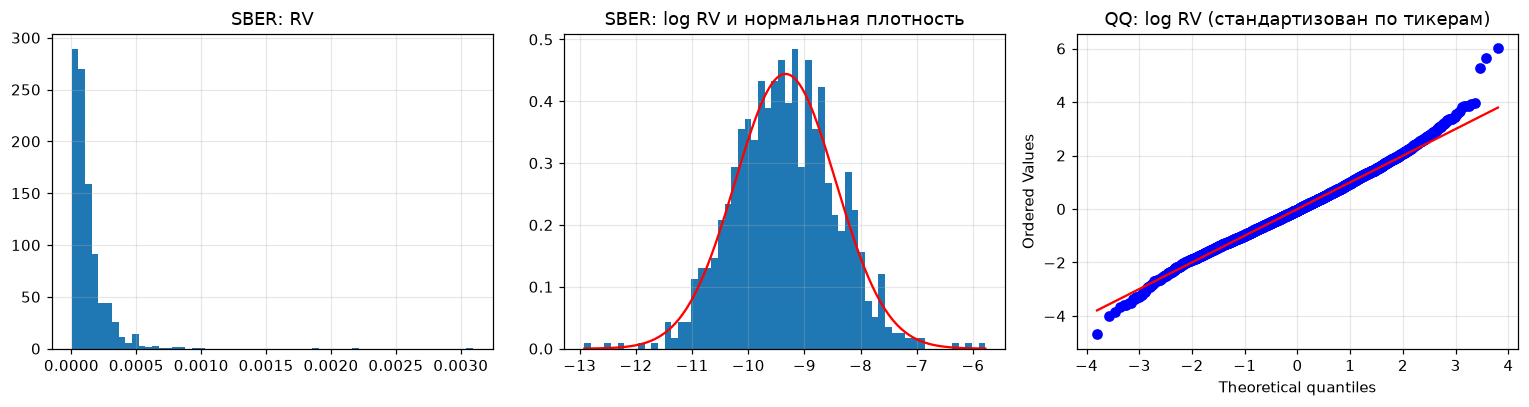

In [5]:
g = good[good["secid"] == REF]
z = good.groupby("secid")["log_rv"].transform(lambda s: (s - s.mean()) / s.std())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(g["rv"], bins=60)
axes[0].set_title(f"{REF}: RV")
axes[1].hist(g["log_rv"], bins=60, density=True)
xs = np.linspace(g["log_rv"].min(), g["log_rv"].max(), 200)
axes[1].plot(xs, stats.norm.pdf(xs, g["log_rv"].mean(), g["log_rv"].std()), "r")
axes[1].set_title(f"{REF}: log RV и нормальная плотность")
stats.probplot(z, dist="norm", plot=axes[2])
axes[2].set_title("QQ: log RV (стандартизован по тикерам)")
plt.tight_layout()
plt.show()

In [6]:
rows = []
for s, gg in good.groupby("secid"):
    jb_rv = stats.jarque_bera(gg["rv"])
    jb_log = stats.jarque_bera(gg["log_rv"])
    adf_p = adfuller(gg["log_rv"].to_numpy(), autolag="AIC")[1]
    rows.append({"secid": s, "JB_p_rv": jb_rv.pvalue, "JB_p_logrv": jb_log.pvalue, "ADF_p_logrv": adf_p})
pd.DataFrame(rows).set_index("secid").round(4)

C:\Users\777\AppData\Local\Temp\ipykernel_652\3435993310.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(gg["log_rv"].to_numpy(), autolag="AIC")[1]
C:\Users\777\AppData\Local\Temp\ipykernel_652\3435993310.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(gg["log_rv"].to_numpy(), autolag="AIC")[1]
C:\Users\777\AppData\Local\Temp\ipyk

,JB_p_rv,JB_p_logrv,ADF_p_logrv
secid,,,
GAZP,0.0,0.2374,0.0616
GMKN,0.0,0.1692,0.0046
LKOH,0.0,0.0000,0.0000
NVTK,0.0,0.0005,0.0000
OZON,0.0,0.0000,0.0000
PLZL,0.0,0.0000,0.0001
ROSN,0.0,0.0106,0.0000
SBER,0.0,0.0559,0.0000
T,0.0,0.0156,0.0000


## 4. Автокорреляция log RV

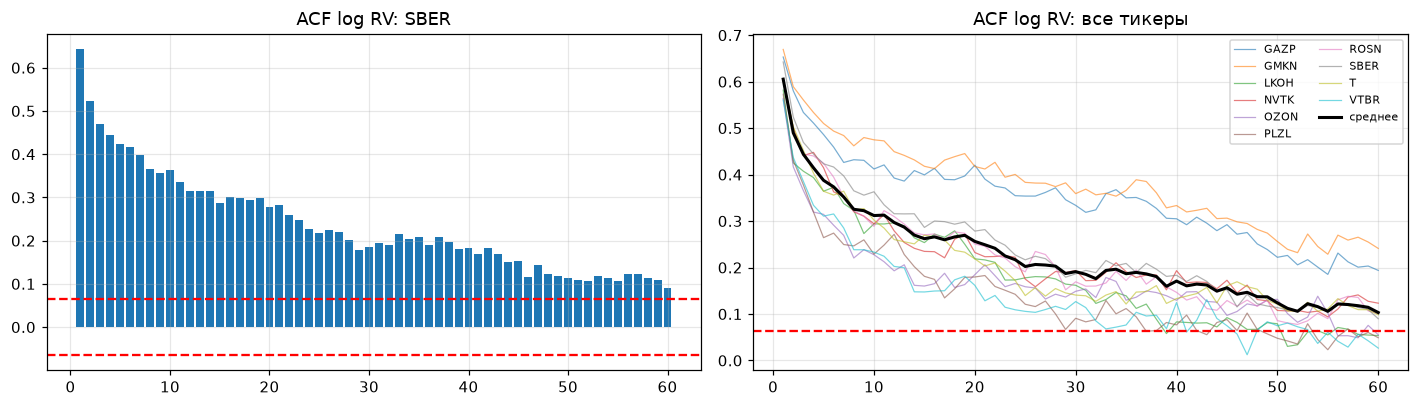

In [7]:
acfs = {s: acf(gg["log_rv"].to_numpy(), nlags=NLAGS, fft=True) for s, gg in good.groupby("secid")}
acf_mean = np.mean(list(acfs.values()), axis=0)
n_min = good.groupby("secid").size().min()
band = 1.96 / np.sqrt(n_min)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
lags = np.arange(NLAGS + 1)
axes[0].bar(lags[1:], acfs[REF][1:], width=0.8)
axes[0].axhline(band, color="r", ls="--")
axes[0].axhline(-band, color="r", ls="--")
axes[0].set_title(f"ACF log RV: {REF}")
for s, a in acfs.items():
    axes[1].plot(lags[1:], a[1:], lw=0.8, alpha=0.6, label=s)
axes[1].plot(lags[1:], acf_mean[1:], "k", lw=2, label="среднее")
axes[1].axhline(band, color="r", ls="--")
axes[1].set_title("ACF log RV: все тикеры")
axes[1].legend(ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

In [8]:
lb = {}
for s, gg in good.groupby("secid"):
    res = acorr_ljungbox(gg["log_rv"].to_numpy(), lags=[5, 22], return_df=True)
    lb[s] = {"LB_p_lag5": res["lb_pvalue"].iloc[0], "LB_p_lag22": res["lb_pvalue"].iloc[1],
             "acf_1": acfs[s][1], "acf_5": acfs[s][5], "acf_22": acfs[s][22]}
pd.DataFrame(lb).T.round(4)

,LB_p_lag5,LB_p_lag22,acf_1,acf_5,acf_22
GAZP,0.0,0.0,0.6530,0.4862,0.3751
GMKN,0.0,0.0,0.6693,0.5101,0.4264
LKOH,0.0,0.0,0.5818,0.3642,0.2111
NVTK,0.0,0.0,0.6025,0.4149,0.2237
OZON,0.0,0.0,0.5639,0.3144,0.1825
PLZL,0.0,0.0,0.5729,0.2643,0.1593
ROSN,0.0,0.0,0.6046,0.4244,0.2271
SBER,0.0,0.0,0.6424,0.4232,0.2591
T,0.0,0.0,0.6028,0.3642,0.2100
VTBR,0.0,0.0,0.5605,0.3106,0.1399


## 5. Кластеризация волатильности

Дневные доходности `ret_day` почти не автокоррелированы, а их модуль и квадрат — сильно (классический признак условной гетероскедастичности).
Серые границы на графике доходностей — \(\pm 2\sqrt{RV^{(22)}_{t-1}}\), то есть только по данным до \(t-1\).

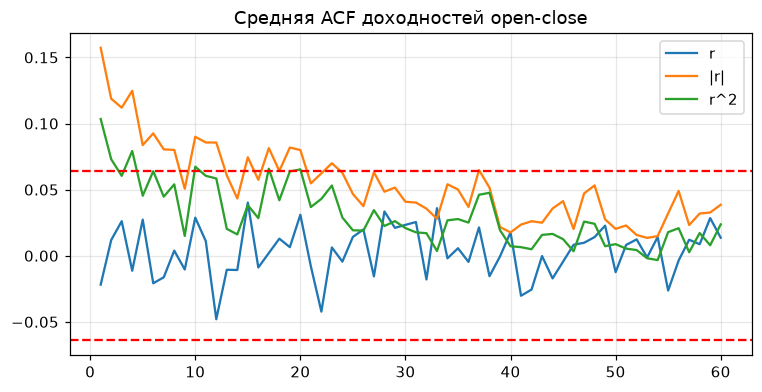

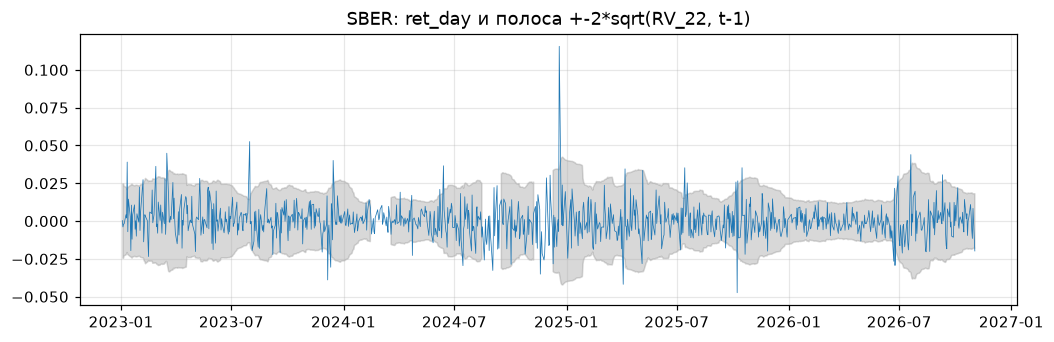

In [9]:
def mean_acf(transform) -> np.ndarray:
    return np.mean([acf(transform(gg["ret_day"].dropna()).to_numpy(), nlags=NLAGS, fft=True)
                    for _, gg in good.groupby("secid")], axis=0)


a_r, a_abs, a_sq = mean_acf(lambda s: s), mean_acf(lambda s: s.abs()), mean_acf(lambda s: s**2)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lags[1:], a_r[1:], label="r")
ax.plot(lags[1:], a_abs[1:], label="|r|")
ax.plot(lags[1:], a_sq[1:], label="r^2")
ax.axhline(band, color="r", ls="--")
ax.axhline(-band, color="r", ls="--")
ax.set_title("Средняя ACF доходностей open-close")
ax.legend()
plt.show()

g = good[good["secid"] == REF].copy()
sigma = 2 * np.sqrt(g["rv_22"].shift(1))
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(g["date"], g["ret_day"], lw=0.5)
ax.fill_between(g["date"], -sigma, sigma, color="gray", alpha=0.3)
ax.set_title(f"{REF}: ret_day и полоса +-2*sqrt(RV_22, t-1)")
plt.show()

In [10]:
arch = {}
for s, gg in good.groupby("secid"):
    r = gg["ret_day"].dropna().to_numpy()
    lm, lm_p, _, _ = het_arch(r - r.mean(), nlags=5)
    arch[s] = {"ARCH_LM_stat": lm, "ARCH_LM_p": lm_p}
pd.DataFrame(arch).T.round(4)

C:\Users\777\Documents\Projects\MOEX\rv-moex\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,ARCH_LM_stat,ARCH_LM_p
GAZP,67.2014,0.0000
GMKN,23.4474,0.0003
LKOH,62.3352,0.0000
NVTK,37.1317,0.0000
OZON,24.9575,0.0001
PLZL,22.2538,0.0005
ROSN,36.2890,0.0000
SBER,3.0452,0.6930
T,10.4326,0.0639
VTBR,2.6918,0.7474


## 6. Сравнение тикеров

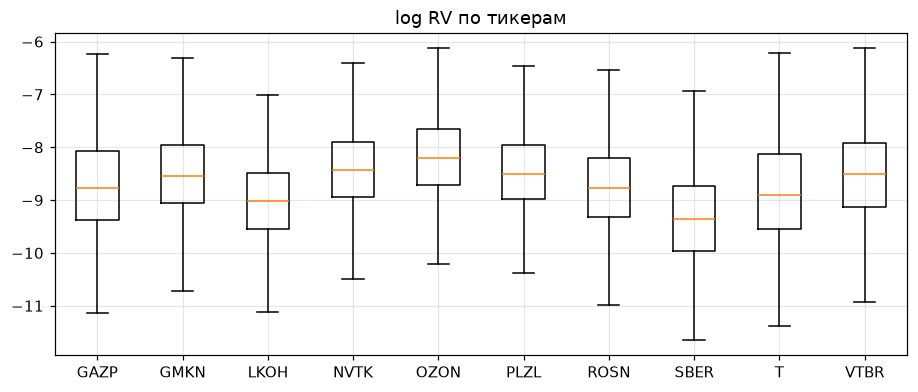

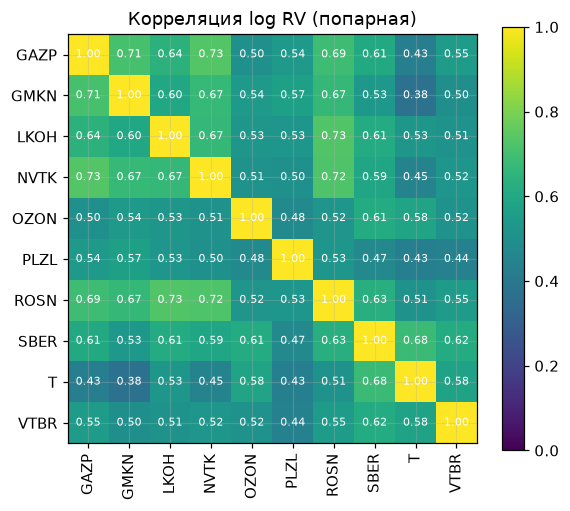

Общих дат для PCA: 903
Доля 1-й главной компоненты: 0.611
Средняя попарная корреляция: 0.564


In [11]:
wide = good.pivot(index="date", columns="secid", values="log_rv")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot([wide[s].dropna() for s in wide.columns], showfliers=False)
ax.set_xticklabels(list(wide.columns))
ax.set_title("log RV по тикерам")
plt.show()

corr = wide.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.to_numpy(), vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
fig.colorbar(im)
ax.set_title("Корреляция log RV (попарная)")
plt.show()

full = wide.dropna()
eig = np.sort(np.linalg.eigvalsh(np.corrcoef(full.to_numpy().T)))[::-1]
off = corr.to_numpy()[~np.eye(len(corr), dtype=bool)]
print(f"Общих дат для PCA: {len(full)}")
print(f"Доля 1-й главной компоненты: {eig[0] / eig.sum():.3f}")
print(f"Средняя попарная корреляция: {off.mean():.3f}")

## 7. Устойчивость по годам (вместо анализа 2022 г.)

secid,GAZP,GMKN,LKOH,NVTK,OZON,PLZL,ROSN,SBER,T,VTBR
year,,,,,,,,,,
2023,-9.230,-9.063,-9.094,-8.803,-8.216,-8.731,-8.892,-9.134,-8.472,-8.512
2024,-8.632,-8.364,-9.086,-8.457,-8.003,-8.532,-8.900,-9.336,-8.543,-8.430
2025,-8.478,-8.253,-9.062,-8.176,-8.291,-8.435,-8.597,-9.307,-9.182,-8.487
2026,-8.634,-8.387,-8.777,-8.240,-8.354,-8.310,-8.581,-9.711,-9.340,-8.553


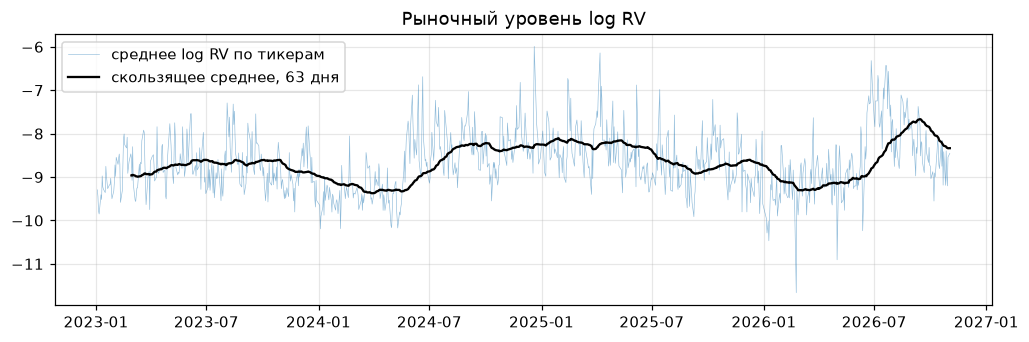

In [12]:
by_year = (good.assign(year=good["date"].dt.year)
           .pivot_table(index="year", columns="secid", values="log_rv", aggfunc="median"))
display(by_year.round(3))

market = wide.mean(axis=1)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(market.index, market, lw=0.4, alpha=0.5, label="среднее log RV по тикерам")
ax.plot(market.index, market.rolling(63, min_periods=40).mean(), "k", lw=1.5, label="скользящее среднее, 63 дня")
ax.legend()
ax.set_title("Рыночный уровень log RV")
plt.show()

## 8. Проверка признаков HAR (описательная)

Регрессия \(\log RV_{t+1}\) на \(\log RV^{(1)}_t,\ \log RV^{(5)}_t,\ \log RV^{(22)}_t\) по всей выборке служит только проверкой согласованности признаков.
Это не оценка качества прогноза: она внутривыборочная и не заменяет walk-forward-валидацию.

In [13]:
def har_design(gg: pd.DataFrame) -> pd.DataFrame:
    gg = gg.sort_values("date")
    ok_next = (gg["date"].shift(-1) - gg["date"]).dt.days <= 10
    y = gg["log_rv"].shift(-1).where(ok_next)
    d = pd.concat([y.rename("y"), gg[["log_rv_1", "log_rv_5", "log_rv_22"]]], axis=1)
    return d.dropna()


def ols(d: pd.DataFrame) -> dict[str, float]:
    X = np.column_stack([np.ones(len(d)), d[["log_rv_1", "log_rv_5", "log_rv_22"]].to_numpy()])
    beta, *_ = np.linalg.lstsq(X, d["y"].to_numpy(), rcond=None)
    resid = d["y"].to_numpy() - X @ beta
    r2 = 1 - resid.var() / d["y"].var(ddof=0)
    return {"const": beta[0], "b_d": beta[1], "b_w": beta[2], "b_m": beta[3],
            "sum_b": beta[1:].sum(), "R2_in_sample": r2, "n": len(d)}


designs = {s: har_design(gg) for s, gg in panel.groupby("secid")}
res = {s: ols(d) for s, d in designs.items()}
res["ALL (pooled)"] = ols(pd.concat(designs.values()))
pd.DataFrame(res).T.round(3)

,const,b_d,b_w,b_m,sum_b,R2_in_sample,n
GAZP,-1.088,0.334,0.183,0.372,0.889,0.473,905.0
GMKN,-0.846,0.312,0.267,0.332,0.911,0.518,878.0
LKOH,-1.735,0.408,0.102,0.308,0.818,0.380,905.0
NVTK,-1.379,0.336,0.290,0.220,0.846,0.418,905.0
OZON,-2.231,0.375,0.199,0.162,0.736,0.331,849.0
PLZL,-2.039,0.441,0.090,0.236,0.767,0.359,902.0
ROSN,-1.564,0.353,0.252,0.226,0.831,0.409,905.0
SBER,-1.594,0.413,0.177,0.250,0.840,0.443,905.0
T,-1.651,0.390,0.168,0.270,0.828,0.405,880.0
VTBR,-2.365,0.374,0.225,0.133,0.732,0.335,901.0


## Выводы

Заполняются по результатам запуска: нормальность log RV, слабое/сильное затухание ACF, различия уровней между тикерами, устойчивость уровня по годам.